
### Part 1: Analyzing Best-Seller Trends Across Product Categories

Objective: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*


In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
%matplotlib inline

In [2]:
df= pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [3]:
df = df[df['stars'] != 0]


In [4]:
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])

crosstab_result

isBestSeller,False,True
category,,
3D Printers,160,1
3D Printing & Scanning,143,2
Abrasive & Finishing Products,229,5
Action Cameras,564,1
Adapters,240,3
...,...,...
Wind Instruments,116,7
Window Treatments,220,5
Women,17274,212


In [5]:
proportion = (crosstab_result[True] / crosstab_result.sum(axis=1)).sort_values(ascending=False)

proportion

category
Material Handling Products        0.121212
Smart Home Security & Lighting    0.077922
Test & Measurement                0.060000
Grocery                           0.058354
Health & Personal Care            0.057747
                                    ...   
Boxes & Organisers                0.000000
Snowboard Boots                   0.000000
Boating Footwear                  0.000000
Blank Media Cases & Wallets       0.000000
eBook Readers & Accessories       0.000000
Length: 296, dtype: float64

2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.



In [25]:
from scipy.stats import chi2_contingency
import pandas as pd


crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])


chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)

chi2_statistic, chi2_p_value


(np.float64(15380.142540443778), np.float64(0.0))

3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

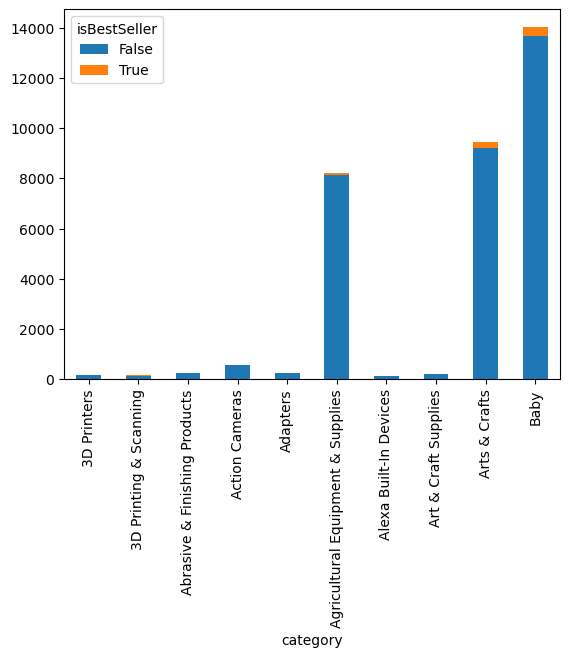

In [ ]:
crosstab_result.head(10).plot(kind="bar", stacked=True)
plt.show()


### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

In [6]:
def amazon_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    
    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Identify the outliers
    outliers = data[(data < lower_bound) | (data > upper_bound)]
    
    return outliers

In [7]:
data_series = df['price'] 
outliers = amazon_outliers(data_series)
print(outliers)

10         139.00
19         164.99
23          98.95
27          79.99
28         289.00
            ...  
2443625     99.95
2443627    152.58
2443638    108.77
2443643    158.99
2443649     79.99
Name: price, Length: 144637, dtype: float64


1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

In [8]:
top20= df['category'].value_counts().nlargest(20)

/var/folders/jv/lpcmj8m91yggsl2fvg3tnx2w0000gn/T/ipykernel_17917/1724127547.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='price', y='category',order=top20, palette="coolwarm")


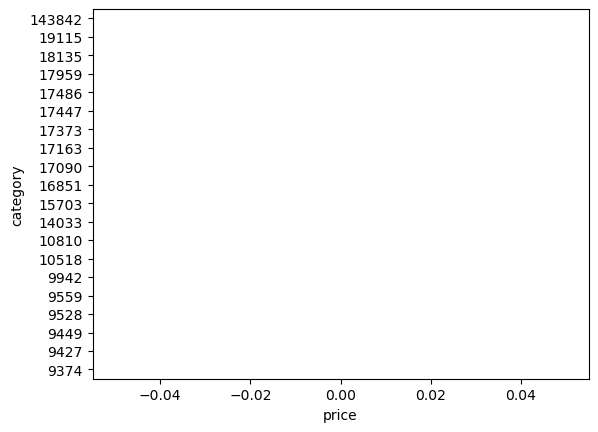

In [9]:
sns.violinplot(data=df, x='price', y='category',order=top20, palette="coolwarm")
plt.show()

In [10]:
print(df.columns)

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')


In [11]:
top20 = df['category'].value_counts().nlargest(20).index
top20

Index(['Sports & Outdoors', 'Beauty', 'Hair Care', 'Skin Care', 'Women',
       'Bath & Body', 'Luggage and travel gear', 'Make-up', 'Men',
       'Manicure & Pedicure Products', 'Fragrances', 'Baby',
       'Handmade Home & Kitchen Products', 'Boys', 'Handmade Gifts',
       'Health & Personal Care', 'Grocery', 'Arts & Crafts',
       'Storage & Organisation', 'Pet Supplies'],
      dtype='object', name='category')

In [12]:
df = df.dropna(subset=['price'])

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
   


In [13]:
top10= df['category'].value_counts().head(10).index
top10

Index(['Sports & Outdoors', 'Beauty', 'Hair Care', 'Skin Care', 'Women',
       'Bath & Body', 'Luggage and travel gear', 'Make-up', 'Men',
       'Manicure & Pedicure Products'],
      dtype='object', name='category')

/var/folders/jv/lpcmj8m91yggsl2fvg3tnx2w0000gn/T/ipykernel_17917/465519113.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


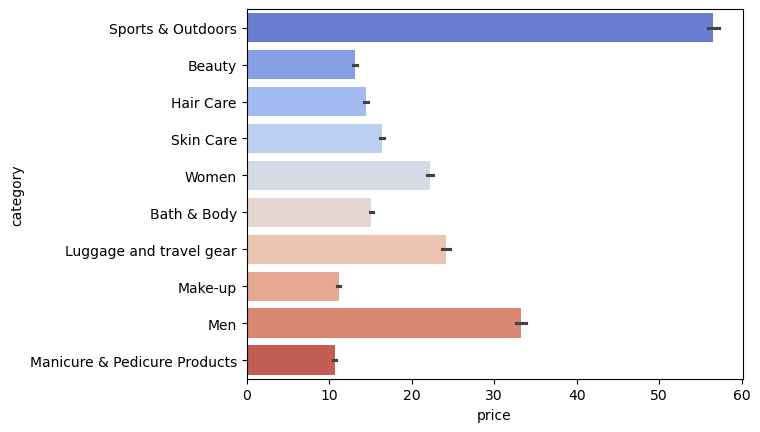

In [14]:
sns.barplot(
    data=df,
    x='price',
    y='category',
    estimator='mean',
    order=top10,
    palette='coolwarm'
)
plt.show()

 - Which product category commands the highest average price? Don't filter here by top categories.
Sports and outdoors

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [15]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443642,2828585,B07DCFQMQL,Speed MaxX BODY ARMOUR CE MOTORBIKE/MOTORCYCLE...,3.6,66,49.99,False,0,Motorbike Clothing
2443643,2828586,B07JM5VQFX,Motorcycle Clothing Suit - Motorbike Suit With...,4.1,5,158.99,False,0,Motorbike Clothing
2443644,2828587,B07X98JLFF,GREAT BIKERS GEAR - Bobber Cafe Brat Style Lea...,3.6,12,14.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


/var/folders/jv/lpcmj8m91yggsl2fvg3tnx2w0000gn/T/ipykernel_17917/48248916.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


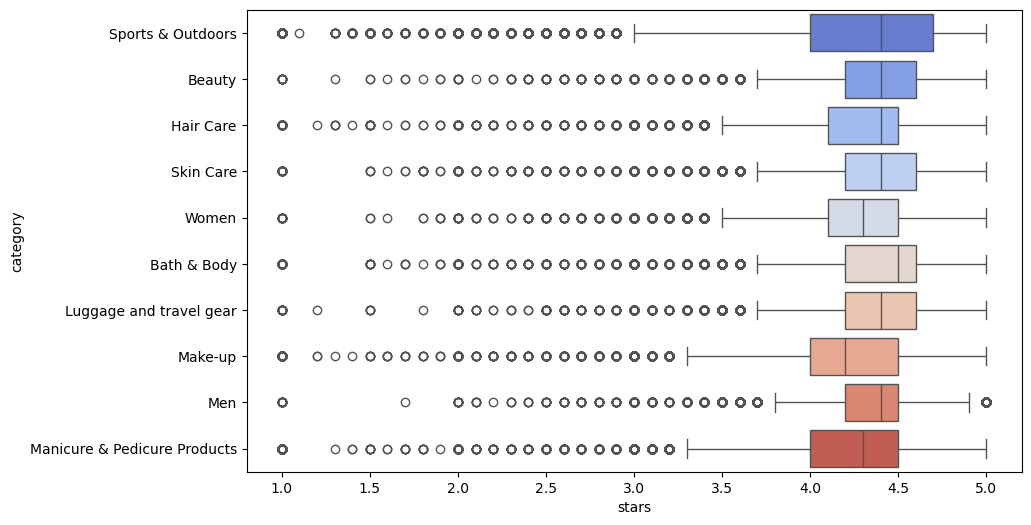

In [16]:
plt.figure(figsize=(10,6))
sns.boxplot(
    data=df,
    x='stars',
    y='category',
    order=top10,
    palette='coolwarm'
)
plt.show()

### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?
	
2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 


In [17]:
correlation = df['price'].corr(df['stars'])
correlation

np.float64(-0.004911823000752948)

Correlacion negativa y muy debil

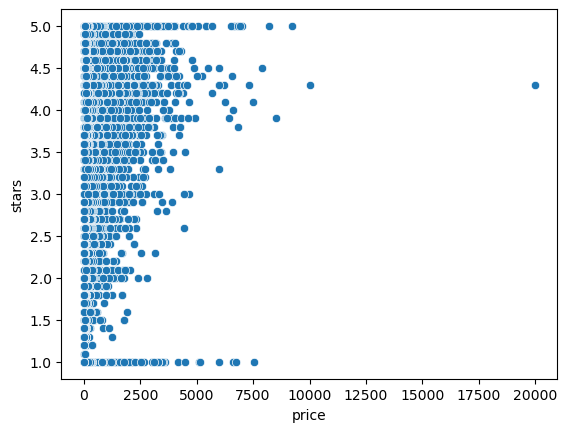

In [18]:
sns.scatterplot(data=df, x='price', y='stars')
plt.show()

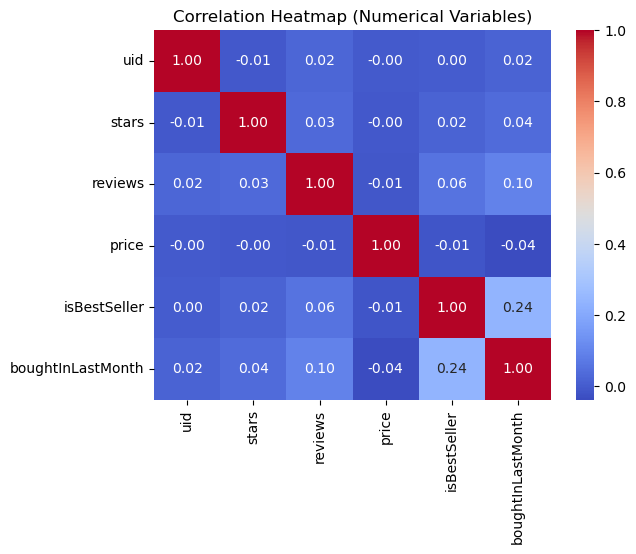

In [19]:
sns.heatmap(
    df.corr(numeric_only=True),    
    annot=True,
    cmap='coolwarm',
    fmt=".2f"
)
plt.title('Correlation Heatmap (Numerical Variables)')
plt.show()

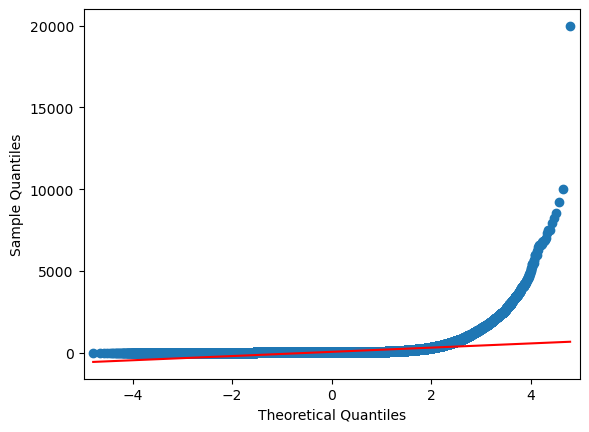

In [20]:
import statsmodels.api as sm
sm.qqplot(df['price'], line='s');
plt.show()